# 01 — data preparation
**Dataset:** Open University Learning Analytics Dataset (OULAD)  

Loads all seven source tables, cleans them, merges into a master student table, and engineers the features used in notebooks 02 and 04.

---
**Before running:** download the data
1. Go to https://www.kaggle.com/datasets/anlgrbz/student-demographics-online-education-dataoulad/data
2. Download
3. Unzip all CSVs into `data/raw/`

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
np.random.seed(42)
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"
import plotly.graph_objects as go
import os


RAW  = '../data/raw/'
PROC = '../data/processed/'
os.makedirs(PROC, exist_ok=True)
os.makedirs('../assets', exist_ok=True)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 120

## Load all tables

In [2]:
courses        = pd.read_csv(RAW + 'courses.csv')
assessments    = pd.read_csv(RAW + 'assessments.csv')
vle            = pd.read_csv(RAW + 'vle.csv')
student_info   = pd.read_csv(RAW + 'studentInfo.csv')
student_reg    = pd.read_csv(RAW + 'studentRegistration.csv')
student_assess = pd.read_csv(RAW + 'studentAssessment.csv')
student_vle    = pd.read_csv(RAW + 'studentVle.csv')

tables = {
    'courses':        courses,
    'assessments':    assessments,
    'vle':            vle,
    'student_info':   student_info,
    'student_reg':    student_reg,
    'student_assess': student_assess,
    'student_vle':    student_vle,
}

# double-quoted f-string so single-quoted literals inside parse correctly on Python <= 3.11
header = f"{'Table':<22} {'Rows':>10} {'Cols':>6}"
print(header)
print('-' * len(header))
for name, df in tables.items():
    print(f"{name:<22} {df.shape[0]:>10,} {df.shape[1]:>6}")
print(f"Enrollments: {len(student_info):,}; distinct students: {student_info.id_student.nunique():,}")

Table                        Rows   Cols
----------------------------------------
courses                        22      3
assessments                   206      6
vle                         6,364      6
student_info               32,593     12
student_reg                32,593      5
student_assess            173,912      5
student_vle            10,655,280      6
Enrollments: 32,593; distinct students: 28,785


## Exploratory data analysis

In [3]:
student_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              31482 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability            32593 non-null  object
 11  final_result          32593 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.0+ MB


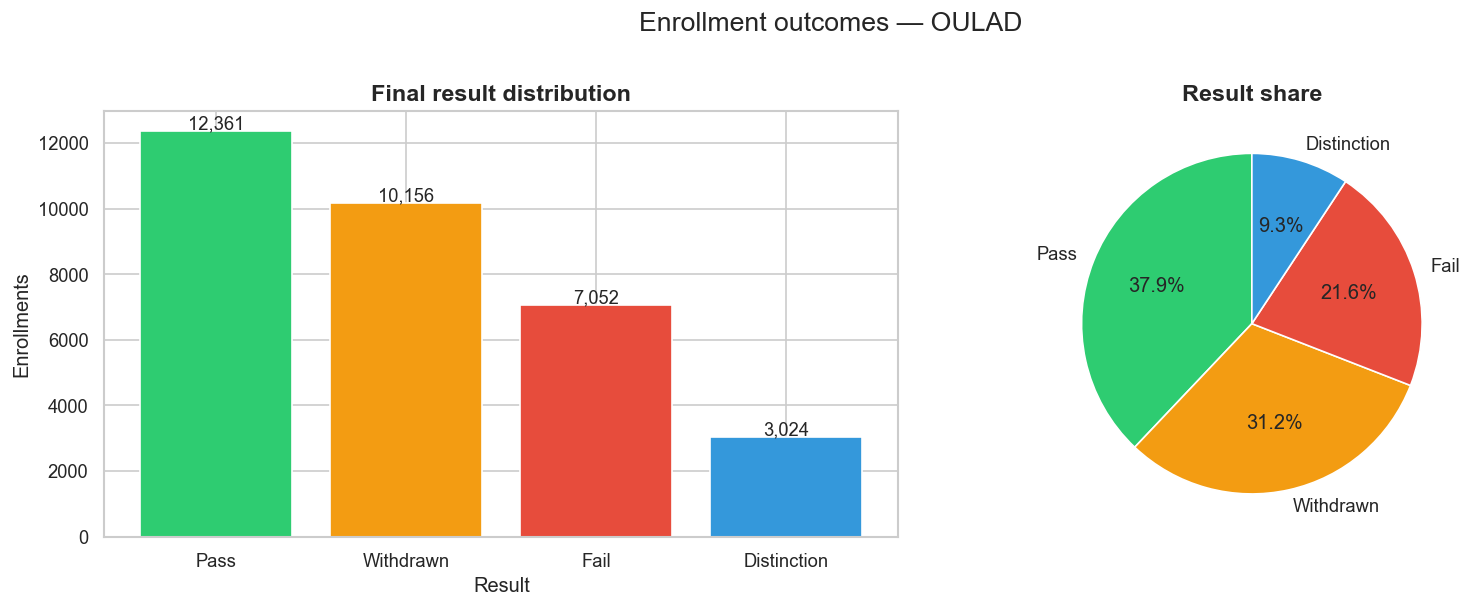


31.2% of enrollments ended with final_result = Withdrawn.
28,785 distinct student IDs across 32,593 module-presentation enrollments.


In [4]:
result_counts = student_info['final_result'].value_counts()

COLORS = {
    'Pass':        '#2ecc71',
    'Distinction': '#3498db',
    'Fail':        '#e74c3c',
    'Withdrawn':   '#f39c12',
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bar_colors = [COLORS[r] for r in result_counts.index]
bars = axes[0].bar(result_counts.index, result_counts.values, color=bar_colors)
axes[0].set_title('Final result distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Result')
axes[0].set_ylabel('Enrollments')
for bar in bars:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 80,
        f'{int(bar.get_height()):,}',
        ha='center', fontsize=11
    )

axes[1].pie(
    result_counts.values,
    labels=result_counts.index,
    colors=bar_colors,
    autopct='%1.1f%%',
    startangle=90
)
axes[1].set_title('Result share', fontsize=14, fontweight='bold')

plt.suptitle('Enrollment outcomes — OULAD', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('../assets/01_result_distribution.png', bbox_inches='tight')
plt.show()

withdrawn_pct = result_counts.get('Withdrawn', 0) / result_counts.sum() * 100
print(f'\n{withdrawn_pct:.1f}% of enrollments ended with final_result = Withdrawn.')
print(f'{student_info["id_student"].nunique():,} distinct student IDs across '
      f'{len(student_info):,} module-presentation enrollments.')


In [5]:
missing = (
    pd.DataFrame({
        'missing_count': student_info.isnull().sum(),
        'missing_pct':   student_info.isnull().mean() * 100
    })
    .query('missing_count > 0')
    .sort_values('missing_pct', ascending=False)
)
print('Missing values in studentInfo:')
print(missing.round(2))

Missing values in studentInfo:
          missing_count  missing_pct
imd_band           1111         3.41


In [6]:
withdrawal_by_module = (
    student_info
    .groupby('code_module')
    .apply(lambda x: (x['final_result'] == 'Withdrawn').mean() * 100)
    .reset_index(name='withdrawal_rate_pct')
    .sort_values('withdrawal_rate_pct', ascending=True)
)

fig = px.bar(
    withdrawal_by_module,
    x='withdrawal_rate_pct', y='code_module',
    orientation='h',
    title='Withdrawal rate by module',
    labels={'withdrawal_rate_pct': 'Withdrawal rate (%)', 'code_module': 'Module'},
    color='withdrawal_rate_pct',
    color_continuous_scale='RdYlGn_r',
    text=withdrawal_by_module['withdrawal_rate_pct'].map('{:.1f}%'.format)
)
fig.update_traces(textposition='outside')
fig.update_layout(coloraxis_showscale=False, height=400)
fig.show()

In [7]:
clicks_per_student = (
    student_vle
    .groupby(['id_student', 'code_module', 'code_presentation'])['sum_click']
    .sum()
    .reset_index(name='total_clicks')
)

print('Click totals per enrollment with VLE records')
print(clicks_per_student.total_clicks.describe().round(1))
p99 = clicks_per_student.total_clicks.quantile(0.99)
shown = clicks_per_student.loc[clicks_per_student.total_clicks.le(p99), 'total_clicks']
# Store histogram bin counts rather than individual enrollment values in the HTML.
counts, edges = np.histogram(shown, bins=60)
fig = go.Figure(go.Bar(x=(edges[1:] + edges[:-1])/2, y=counts, width=np.diff(edges)))
fig.update_layout(title=f'Clicks per enrollment up to the 99th percentile ({p99:.0f})',
                  xaxis_title='Total clicks', yaxis_title='Enrollments')
fig.show()

Click totals per enrollment with VLE records
count    29228.0
mean      1355.0
std       1733.5
min          1.0
25%        260.8
50%        739.5
75%       1770.0
max      24139.0
Name: total_clicks, dtype: float64


In [8]:
# Descriptive relationship using full-course clicks
temp = clicks_per_student.merge(
    student_info[['id_student','code_module','code_presentation','final_result']],
    on=['id_student','code_module','code_presentation']
)
print('Avg clicks by outcome:')
print(
    temp.groupby('final_result')['total_clicks']
    .mean()
    .sort_values(ascending=False)
    .map('{:,.0f}'.format)
)

Avg clicks by outcome:
final_result
Distinction    2,667
Pass           1,922
Fail             688
Withdrawn        445
Name: total_clicks, dtype: object


## Data cleaning

In [9]:
si = student_info.copy()

# imd_band (Index of Multiple Deprivation) — keep a missing category for the descriptive master table
si['imd_band'] = si['imd_band'].fillna('Missing')

# ordered category so plots sort correctly
age_order = ['0-35', '35-55', '55<=']
si['age_band'] = pd.Categorical(si['age_band'], categories=age_order, ordered=True)

si['completed'] = si['final_result'].isin(['Pass', 'Distinction']).astype(int)
si['withdrew']  = (si['final_result'] == 'Withdrawn').astype(int)

assert si.isnull().sum().sum() == 0, 'unexpected nulls after cleaning'
print(f'studentInfo: {si.shape[0]:,} rows, 0 nulls')

studentInfo: 32,593 rows, 0 nulls


In [10]:
sr = student_reg.copy()

# Negative values are valid withdrawal dates relative to the course start.
sr['churned'] = sr['date_unregistration'].notna().astype(int)
print(f'Registrations with a recorded unregistration date: {sr["churned"].mean():.1%}')


Registrations with a recorded unregistration date: 30.9%


In [11]:
sa = student_assess.copy()

# A recorded submission can have no mark. Keep missing marks unknown.
sa['submitted'] = sa['score'].notna().astype(int)
sa['is_banked'] = sa['is_banked'].astype(int)

print(f'Share of submission records with a mark: {sa["submitted"].mean() * 100:.1f}%')
print(f'Avg score (submitted only): {sa.loc[sa["submitted"] == 1, "score"].mean():.1f}')

Share of submission records with a mark: 99.9%
Avg score (submitted only): 75.8


## Build the master student table

Assessment stats must be aggregated at `(id_student, code_module, code_presentation)`, not just `id_student`. A student taking three modules has three separate sets of assessments — grouping only by `id_student` and joining into master would duplicate cross-module totals across every row for that student, corrupting the funnel counts.

A row in studentAssessment is a recorded submission. In the legacy output schema, submission_count counts rows with a mark and submission_rate is their share of recorded rows. Scores average available marks only. An enrollment without any mark has a missing mean score.

In [12]:
# one row per (student, module, presentation)
engagement = (
    student_vle
    .groupby(['id_student', 'code_module', 'code_presentation'])
    .agg(
        total_clicks   = ('sum_click', 'sum'),
        active_days    = ('date', 'nunique'),
        first_activity = ('date', 'min'),
        last_activity  = ('date', 'max'),
    )
    .reset_index()
)
print(f'Engagement: {engagement.shape[0]:,} rows')

Engagement: 29,228 rows


In [13]:
# join with assessments to get code_module and code_presentation per row
sa_with_module = sa.merge(
    assessments[['id_assessment', 'code_module', 'code_presentation']],
    on='id_assessment',
    how='left'
)

assess_stats = (
    sa_with_module
    .groupby(['id_student', 'code_module', 'code_presentation'])
    .agg(
        avg_score         = ('score', 'mean'),
        submission_count  = ('submitted', 'sum'),
        total_assessments = ('submitted', 'count'),
    )
    .reset_index()
)
assess_stats['submission_rate'] = (
    assess_stats['submission_count'] / assess_stats['total_assessments']
)
print(f'Assessment stats: {assess_stats.shape[0]:,} rows')


Assessment stats: 25,843 rows


In [14]:
master = (
    si
    .merge(
        sr[['id_student','code_module','code_presentation',
            'date_registration','date_unregistration','churned']],
        on=['id_student','code_module','code_presentation'],
        how='left', validate='one_to_one'
    )
    .merge(engagement,   on=['id_student','code_module','code_presentation'], how='left', validate='one_to_one')
    .merge(assess_stats, on=['id_student','code_module','code_presentation'], how='left', validate='one_to_one')
)

eng_cols    = ['total_clicks','active_days']
assess_cols = ['submission_count','total_assessments','submission_rate']
master[eng_cols]    = master[eng_cols].fillna(0)
master[assess_cols] = master[assess_cols].fillna(0)

print(f'Master: {master.shape[0]:,} rows × {master.shape[1]} columns')

Master: 32,593 rows × 25 columns


## Feature engineering

In [15]:
keys = ['id_student', 'code_module', 'code_presentation']
early_clicks = student_vle.loc[
    student_vle['date'].between(0, 13) & student_vle['sum_click'].gt(0), keys
].drop_duplicates()
master['early_active'] = pd.MultiIndex.from_frame(master[keys]).isin(
    pd.MultiIndex.from_frame(early_clicks)
).astype(int)

# click volume buckets: Inactive / Low / Medium / High
master['engagement_tier'] = pd.cut(
    master['total_clicks'],
    bins=[-1, 0, 500, 2000, float('inf')],
    labels=['Inactive', 'Low', 'Medium', 'High']
)

# 0 for inactive students (avoids divide-by-zero)
master['clicks_per_active_day'] = np.where(
    master['active_days'] > 0,
    master['total_clicks'] / master['active_days'],
    0
)

# reduces skew for any downstream modelling
master['log_clicks'] = np.log1p(master['total_clicks'])

# Retrospective flag using full-course submissions
master['at_risk'] = (
    (master['early_active'] == 0) &
    (master['submission_rate'] < 0.5)
).astype(int)

print('Completion rate by tier:')
print(
    master.groupby('engagement_tier', observed=True)[['completed','withdrew']]
    .mean()
    .mul(100)
    .round(1)
    .rename(columns={'completed': 'completion_%', 'withdrew': 'withdrawal_%'})
)

Completion rate by tier:
                 completion_%  withdrawal_%
engagement_tier                            
Inactive                  0.1          88.8
Low                      19.5          45.3
Medium                   65.8          15.5
High                     88.6           3.3


In [16]:
tier_summary = (
    master
    .groupby('engagement_tier', observed=True)['completed']
    .agg(completion_rate='mean', n='count')
    .reset_index()
)

fig = px.bar(
    tier_summary,
    x='engagement_tier', y='completion_rate',
    title='Completion rate by engagement tier',
    text=tier_summary['completion_rate'].map('{:.0%}'.format),
    color='completion_rate',
    color_continuous_scale='Blues',
    labels={'completion_rate': 'Completion rate', 'engagement_tier': 'Tier'}
)
fig.update_traces(textposition='outside')
fig.update_layout(coloraxis_showscale=False, yaxis_tickformat='.0%')
fig.show()

In [17]:
early_summary = master.groupby('early_active')['completed'].agg(
    enrollments='size', completion_rate='mean'
).rename(index={0: 'No clicks on days 0–13', 1: 'Clicked on days 0–13'})
print(early_summary.to_string(formatters={'completion_rate': '{:.1%}'.format}))
rates = early_summary['completion_rate']
print(f'Difference: {(rates.iloc[1] - rates.iloc[0]) * 100:+.1f} pp')
print(f'Rate ratio: {rates.iloc[1] / rates.iloc[0]:.2f}×')


                        enrollments completion_rate
early_active                                       
No clicks on days 0–13         6168           12.4%
Clicked on days 0–13          26425           55.3%
Difference: +42.9 pp
Rate ratio: 4.46×


## Save processed data

In [18]:
master.to_csv(PROC + 'master_students.csv', index=False)
engagement.to_csv(PROC + 'engagement.csv', index=False)
assess_stats.to_csv(PROC + 'assess_stats.csv', index=False)
sr.to_csv(PROC + 'student_reg_clean.csv', index=False)

print('Saved to data/processed/:')
for f in sorted(f for f in os.listdir(PROC) if f.endswith(".csv")):
    size_kb = os.path.getsize(os.path.join(PROC, f)) / 1024
    print(f'  {f:<35}  {size_kb:>7.0f} KB')

print(f'\nmaster: {master.shape[0]:,} rows × {master.shape[1]} columns')

Saved to data/processed/:
  assess_stats.csv                         920 KB
  engagement.csv                           901 KB
  master_students.csv                     5694 KB
  student_reg_clean.csv                    881 KB
  weekly_retention.csv                       4 KB

master: 32,593 rows × 30 columns
